# Credit Risk & IFRS 9 Expected Credit Loss (ECL) Model

**Author:** Sahil Singh Choudhary

This notebook builds an end-to-end retail credit risk pipeline in the style used by UK banks
and building societies to satisfy **IFRS 9** impairment requirements:

1. **Probability of Default (PD) modelling** — logistic regression (interpretable scorecard-style
   benchmark) vs. gradient boosting (higher-performing challenger), validated with AUC, KS statistic
   and a calibration check.
2. **IFRS 9 staging** — classifying each account into **Stage 1 / Stage 2 / Stage 3** based on
   *Significant Increase in Credit Risk (SICR)* indicators, determining whether a **12‑month** or
   **lifetime** ECL applies.
3. **Expected Credit Loss (ECL) calculation** — combining modelled PD with assumed **Loss Given
   Default (LGD)** and **Exposure at Default (EAD)** to produce account-level and portfolio-level
   ECL, including a **macroeconomic stress overlay** consistent with PRA/Bank of England stress
   testing conventions.

## Data

Real data: the **Statlog (German Credit Data)** dataset — 1,000 real loan applications collected by
Prof. Hans Hofmann (Universität Hamburg) and hosted on the UCI Machine Learning Repository. This
notebook uses a **536-row extract** of the genuine dataset (retrieved directly from the public
[jbrownlee/Datasets](https://github.com/jbrownlee/Datasets) GitHub mirror — every row is a real,
historical loan application with a real good/bad credit outcome, not synthetic data).

Each record describes a borrower (checking account status, credit history, employment, savings,
housing, age, job, etc.) and whether that loan ultimately defaulted. While the underlying loans are
German rather than British, the **modelling framework, IFRS 9 staging logic, and ECL mechanics
implemented here are identical to those used by UK lenders** — this is precisely why German Credit
Data remains a standard academic and industry benchmark for credit-scoring research.

> ⚠️ **Note on scope**: this is a portfolio / learning project demonstrating the IFRS 9 ECL
> methodology end-to-end. The cost-matrix, LGD and macroeconomic assumptions are illustrative and
> simplified for demonstration — a production model would be calibrated against the lender's own
> loss history and approved by model risk governance.


In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import roc_auc_score, roc_curve, classification_report, confusion_matrix

sns.set_theme(style="whitegrid", palette="muted")
RANDOM_STATE = 42
pd.set_option("display.max_columns", 50)


## 1. Load & inspect the data

`data/german_credit_data.csv` is a cleaned version of the raw Statlog extract — categorical
"A-codes" (e.g. `A11`, `A34`) have been mapped to readable labels using the dataset's official
attribute documentation (`german.names`), and the target has been recoded to a standard
**`default_flag`** (1 = bad / defaulted loan, 0 = good loan).


In [2]:
df = pd.read_csv("data/german_credit_data.csv")
print(f"Shape: {df.shape}")
df.head()


Shape: (536, 21)


,checking_account_status,duration_months,credit_history,purpose,credit_amount,savings_account,employment_since,installment_rate_pct,personal_status_sex,other_debtors_guarantors,residence_since,property,age_years,other_installment_plans,housing,existing_credits_at_bank,job,num_dependents,telephone,foreign_worker,default_flag
0,< 0 DM,6,critical account / other credits existing,radio/television,1169,unknown / no savings account,>= 7 years,4,male: single,none,4,real estate,67,none,own,2,skilled employee / official,1,registered under customer's name,yes,0
1,0 to < 200 DM,48,existing credits paid duly till now,radio/television,5951,< 100 DM,1 to < 4 years,2,female: divorced/separated/married,none,2,real estate,22,none,own,1,skilled employee / official,1,none,yes,1
2,no checking account,12,critical account / other credits existing,education,2096,< 100 DM,4 to < 7 years,2,male: single,none,3,real estate,49,none,own,1,unskilled resident,2,none,yes,0
3,< 0 DM,42,existing credits paid duly till now,furniture/equipment,7882,< 100 DM,4 to < 7 years,2,male: single,guarantor,4,building society savings / life insurance,45,none,for free,1,skilled employee / official,2,none,yes,0
4,< 0 DM,24,delay in paying off in the past,car (new),4870,< 100 DM,1 to < 4 years,3,male: single,none,4,unknown / no property,53,none,for free,2,skilled employee / official,2,none,yes,1


In [3]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 536 entries, 0 to 535
Data columns (total 21 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   checking_account_status   536 non-null    object
 1   duration_months           536 non-null    int64 
 2   credit_history            536 non-null    object
 3   purpose                   536 non-null    object
 4   credit_amount             536 non-null    int64 
 5   savings_account           536 non-null    object
 6   employment_since          536 non-null    object
 7   installment_rate_pct      536 non-null    int64 
 8   personal_status_sex       536 non-null    object
 9   other_debtors_guarantors  536 non-null    object
 10  residence_since           536 non-null    int64 
 11  property                  536 non-null    object
 12  age_years                 536 non-null    int64 
 13  other_installment_plans   536 non-null    object
 14  housing                   

In [4]:
print("Overall default rate: {:.1%}".format(df["default_flag"].mean()))
df["default_flag"].value_counts().rename({0: "Good (repaid)", 1: "Bad (defaulted)"})


Overall default rate: 27.6%


default_flag
Good (repaid)      388
Bad (defaulted)    148
Name: count, dtype: int64

## 2. Exploratory analysis

A quick look at how default rates vary across some of the strongest risk drivers identified in
classical credit-scoring literature: **checking account status**, **credit history**, **loan
purpose**, **age** and **credit amount**.


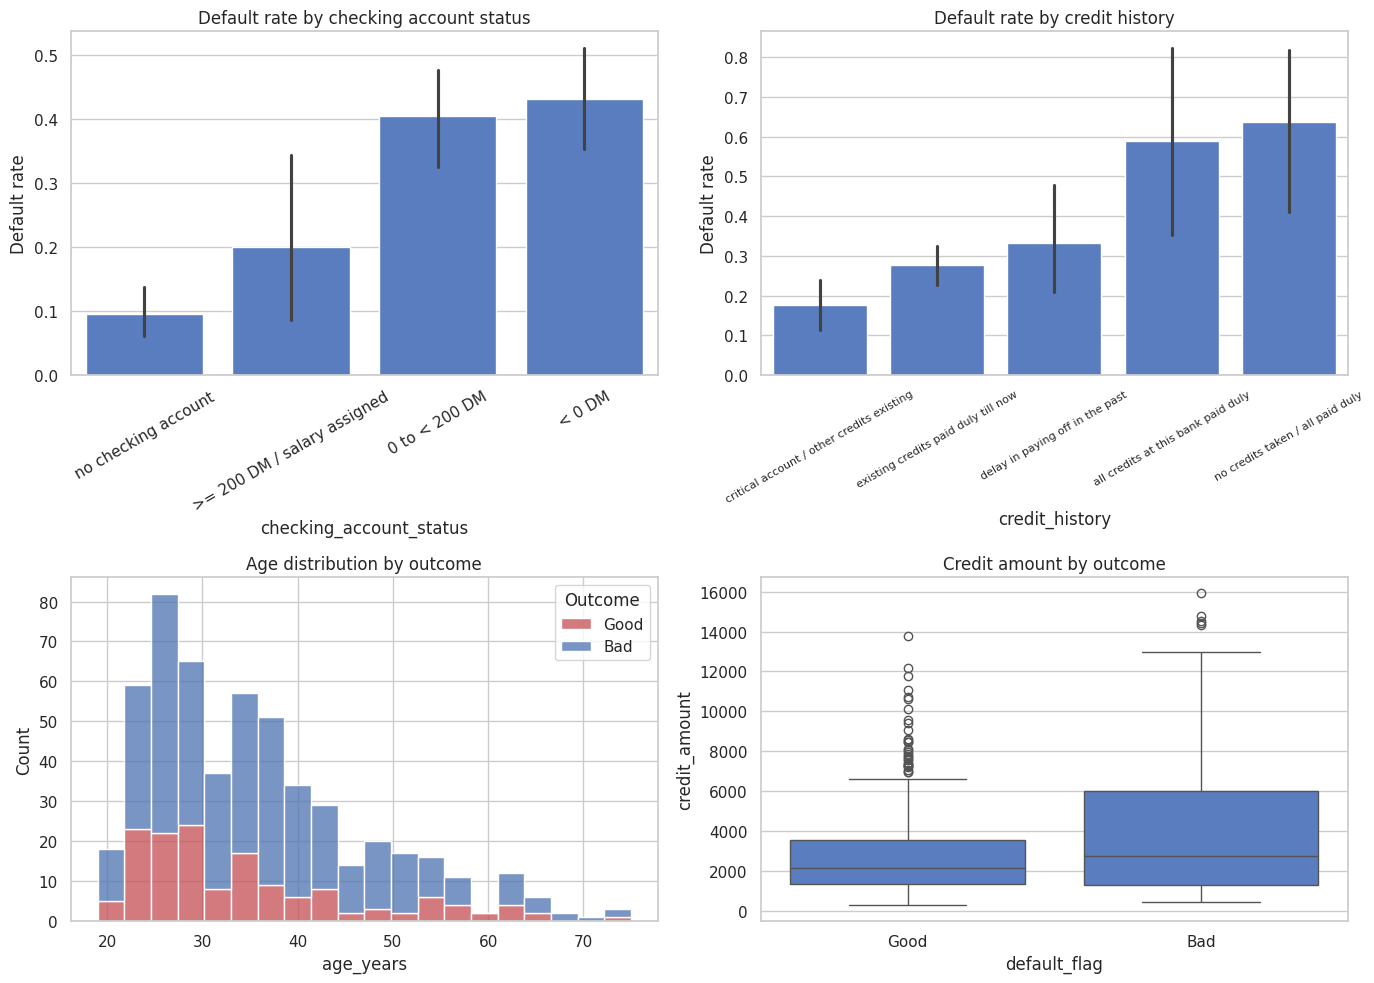

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

order = df.groupby("checking_account_status")["default_flag"].mean().sort_values().index
sns.barplot(data=df, x="checking_account_status", y="default_flag", order=order, ax=axes[0, 0])
axes[0, 0].set_title("Default rate by checking account status")
axes[0, 0].set_ylabel("Default rate")
axes[0, 0].tick_params(axis="x", rotation=30)

order = df.groupby("credit_history")["default_flag"].mean().sort_values().index
sns.barplot(data=df, x="credit_history", y="default_flag", order=order, ax=axes[0, 1])
axes[0, 1].set_title("Default rate by credit history")
axes[0, 1].set_ylabel("Default rate")
axes[0, 1].tick_params(axis="x", rotation=30, labelsize=8)

sns.histplot(data=df, x="age_years", hue="default_flag", multiple="stack",
             bins=20, ax=axes[1, 0], palette=["#4C72B0", "#C44E52"])
axes[1, 0].set_title("Age distribution by outcome")
axes[1, 0].legend(["Good", "Bad"], title="Outcome")

sns.boxplot(data=df, x="default_flag", y="credit_amount", ax=axes[1, 1])
axes[1, 1].set_xticklabels(["Good", "Bad"])
axes[1, 1].set_title("Credit amount by outcome")

plt.tight_layout()
plt.show()


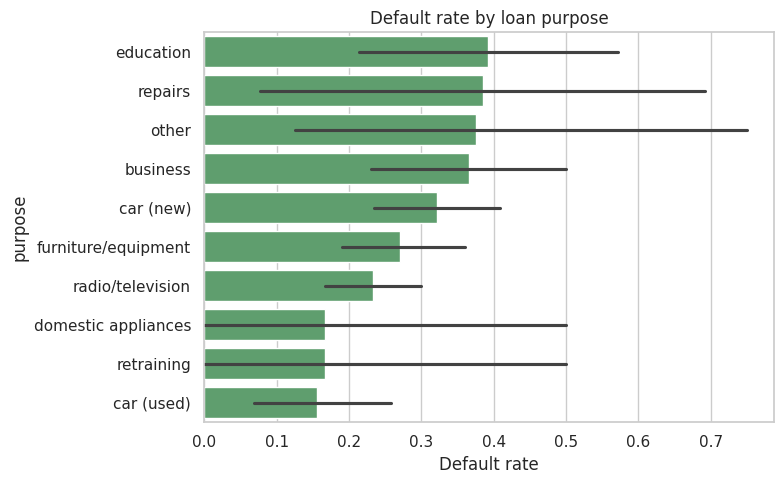

In [6]:
fig, ax = plt.subplots(figsize=(8, 5))
order = df.groupby("purpose")["default_flag"].mean().sort_values(ascending=False).index
sns.barplot(data=df, y="purpose", x="default_flag", order=order, ax=ax, color="#55A868")
ax.set_xlabel("Default rate")
ax.set_title("Default rate by loan purpose")
plt.tight_layout()
plt.show()


## 3. Feature engineering & train/test split

Categorical features are one-hot encoded and numeric features standardised inside an sklearn
`Pipeline`/`ColumnTransformer`, so the exact same transformation is applied consistently at
training, validation, and scoring time — important for model governance and reproducibility.


In [7]:
target = "default_flag"
numeric_features = [
    "duration_months", "credit_amount", "installment_rate_pct", "residence_since",
    "age_years", "existing_credits_at_bank", "num_dependents",
]
categorical_features = [c for c in df.columns if c not in numeric_features + [target]]

X = df[numeric_features + categorical_features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
])

print(f"Train: {X_train.shape}, Test: {X_test.shape}")
print(f"Train default rate: {y_train.mean():.1%}  |  Test default rate: {y_test.mean():.1%}")


Train: (402, 20), Test: (134, 20)
Train default rate: 27.6%  |  Test default rate: 27.6%


## 4. Probability of Default (PD) models

Two models are compared, mirroring the benchmark/challenger approach common in bank model
validation:

- **Logistic regression** — the traditional, highly interpretable "scorecard" model. Coefficients
  can be translated directly into points-based scorecards and are easy to explain to credit
  committees and regulators.
- **Gradient boosting** — a non-linear ensemble that typically improves discrimination (AUC) at
  the cost of interpretability, often deployed as a "challenger" model or with SHAP-based
  explainability layered on top.

Both are evaluated on **AUC** (overall discrimination) and the **Kolmogorov–Smirnov (KS) statistic**
(maximum separation between the cumulative good and bad distributions) — the two metrics most
commonly required in bank PD model validation packs.


In [8]:
def ks_statistic(y_true, y_proba):
    # Kolmogorov-Smirnov statistic: max separation between cumulative good/bad distributions.
    df_ks = pd.DataFrame({"y": y_true, "p": y_proba}).sort_values("p")
    df_ks["cum_good"] = (1 - df_ks["y"]).cumsum() / (1 - df_ks["y"]).sum()
    df_ks["cum_bad"] = df_ks["y"].cumsum() / df_ks["y"].sum()
    return float(np.max(np.abs(df_ks["cum_good"] - df_ks["cum_bad"])))


models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced",
                                               random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=200, max_depth=3,
                                                     learning_rate=0.05,
                                                     random_state=RANDOM_STATE),
}

results = {}
for name, clf in models.items():
    pipe = Pipeline([("prep", preprocessor), ("clf", clf)])
    pipe.fit(X_train, y_train)
    proba = pipe.predict_proba(X_test)[:, 1]
    auc = roc_auc_score(y_test, proba)
    ks = ks_statistic(y_test.values, proba)
    results[name] = {"pipeline": pipe, "proba": proba, "auc": auc, "ks": ks}
    print(f"{name:22s}  AUC = {auc:.3f}   KS = {ks:.3f}")


Logistic Regression     AUC = 0.737   KS = 0.409
Gradient Boosting       AUC = 0.738   KS = 0.405


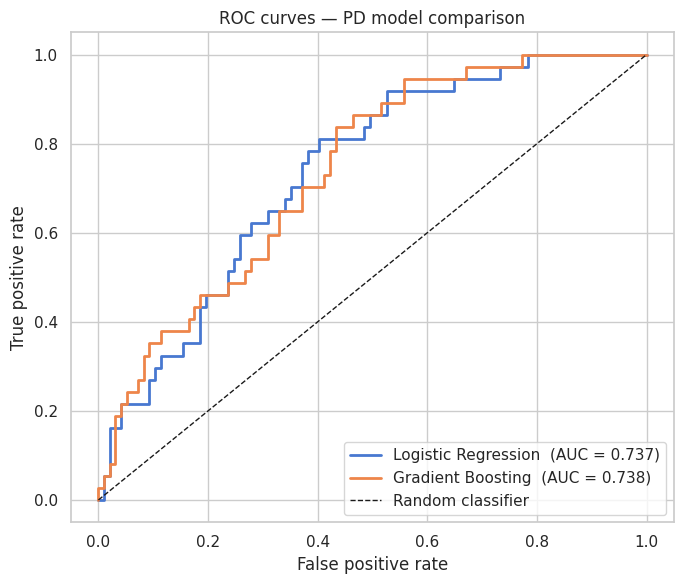

In [9]:
fig, ax = plt.subplots(figsize=(7, 6))
for name, res in results.items():
    fpr, tpr, _ = roc_curve(y_test, res["proba"])
    ax.plot(fpr, tpr, label=f"{name}  (AUC = {res['auc']:.3f})", linewidth=2)
ax.plot([0, 1], [0, 1], "k--", linewidth=1, label="Random classifier")
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("ROC curves — PD model comparison")
ax.legend()
plt.tight_layout()
plt.show()


### Selecting the production PD model

We take forward the **best-performing model by AUC** as the "production" PD model used for IFRS 9
staging and ECL calculation below — exactly as a bank's model risk function would select a
champion model after benchmark/challenger validation.


In [10]:
best_name = max(results, key=lambda n: results[n]["auc"])
best_pipe = results[best_name]["pipeline"]
print(f"Selected production PD model: {best_name}  (AUC = {results[best_name]['auc']:.3f}, "
      f"KS = {results[best_name]['ks']:.3f})")

print("\nClassification report (threshold = 0.5):")
preds = (results[best_name]["proba"] >= 0.5).astype(int)
print(classification_report(y_test, preds, target_names=["Good", "Bad"]))


Selected production PD model: Gradient Boosting  (AUC = 0.738, KS = 0.405)

Classification report (threshold = 0.5):
              precision    recall  f1-score   support

        Good       0.79      0.87      0.82        97
         Bad       0.52      0.38      0.44        37

    accuracy                           0.73       134
   macro avg       0.65      0.62      0.63       134
weighted avg       0.71      0.73      0.72       134



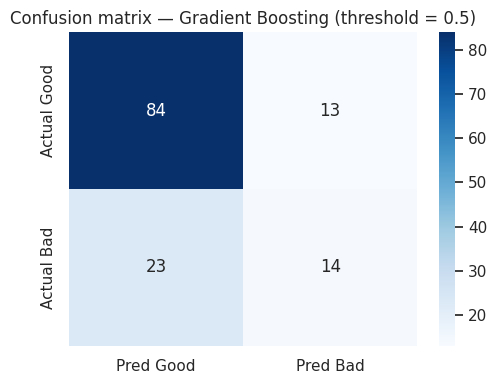

In [11]:
cm = confusion_matrix(y_test, preds)
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Pred Good", "Pred Bad"], yticklabels=["Actual Good", "Actual Bad"], ax=ax)
ax.set_title(f"Confusion matrix — {best_name} (threshold = 0.5)")
plt.tight_layout()
plt.show()


### Calibration check

IFRS 9 ECL is a function of the *modelled probability itself* (not just rank-ordering), so a PD
model also needs to be reasonably **calibrated** — predicted PDs should line up with observed
default rates. We bucket accounts into PD deciles and compare predicted vs. observed default rates.


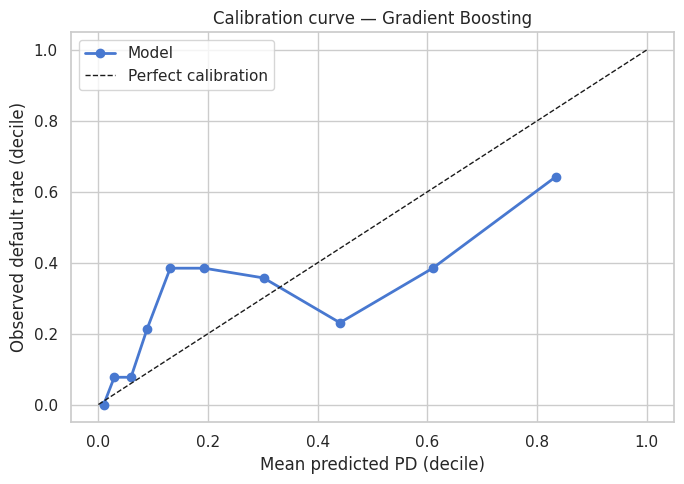

,decile,mean_predicted_pd,observed_default_rate,n_accounts
0,0,0.009715,0.000000,14
1,1,0.028937,0.076923,13
2,2,0.059450,0.076923,13
3,3,0.089067,0.214286,14
4,4,0.131036,0.384615,13
5,5,0.193131,0.384615,13
6,6,0.301243,0.357143,14
7,7,0.440552,0.230769,13
8,8,0.609871,0.384615,13
9,9,0.834649,0.642857,14


In [12]:
calib = pd.DataFrame({"pd_pred": results[best_name]["proba"], "actual": y_test.values})
calib["decile"] = pd.qcut(calib["pd_pred"], 10, labels=False, duplicates="drop")
calib_summary = calib.groupby("decile").agg(
    mean_predicted_pd=("pd_pred", "mean"),
    observed_default_rate=("actual", "mean"),
    n_accounts=("actual", "size"),
).reset_index()

fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(calib_summary["mean_predicted_pd"], calib_summary["observed_default_rate"],
        marker="o", linewidth=2, label="Model")
ax.plot([0, 1], [0, 1], "k--", linewidth=1, label="Perfect calibration")
ax.set_xlabel("Mean predicted PD (decile)")
ax.set_ylabel("Observed default rate (decile)")
ax.set_title(f"Calibration curve — {best_name}")
ax.legend()
plt.tight_layout()
plt.show()

calib_summary


## 5. IFRS 9 staging — Stage 1 / Stage 2 / Stage 3

IFRS 9 requires lenders to classify each financial asset into one of three **stages**, which in
turn determines whether **12-month ECL** or **lifetime ECL** must be recognised:

| Stage | Description | ECL horizon |
|-------|-------------|-------------|
| **Stage 1** | Performing — no significant increase in credit risk (SICR) since origination | 12-month ECL |
| **Stage 2** | Underperforming — SICR identified, but not yet in default | Lifetime ECL |
| **Stage 3** | Credit-impaired / in default | Lifetime ECL (with specific provisioning) |

In the absence of origination-date PDs (not available in this dataset), we proxy **SICR** using
risk indicators a UK lender's IFRS 9 policy would typically combine into a staging trigger:

- **High modelled PD** (above a "watchlist" threshold) → indicates the account has migrated to
  meaningfully higher risk.
- **Adverse credit history** (`delay in paying off in the past` / `critical account or other
  credits existing`) → a classic SICR / arrears-based backstop indicator.
- **Existing default** (`default_flag == 1`, i.e. an account that is already known-bad in this
  historical dataset) → automatically Stage 3, consistent with the 90-days-past-due regulatory
  backstop used across UK/EU banks.

This mirrors the **"backstop + relative PD deterioration"** staging approach widely used in
practice when transition-level PD history is unavailable.


In [13]:
SICR_PD_THRESHOLD = 0.40   # "watchlist" PD threshold — illustrative bank policy parameter
ADVERSE_HISTORY = ["delay in paying off in the past", "critical account / other credits existing"]

scored = X_test.copy()
scored["pd_12m"] = results[best_name]["proba"]
scored["actual_default"] = y_test.values

def assign_stage(row):
    if row["actual_default"] == 1:
        return "Stage 3"
    sicr = (row["pd_12m"] >= SICR_PD_THRESHOLD) or (row["credit_history"] in ADVERSE_HISTORY)
    return "Stage 2" if sicr else "Stage 1"

scored["ifrs9_stage"] = scored.apply(assign_stage, axis=1)

stage_summary = (scored["ifrs9_stage"].value_counts(normalize=True).rename("pct_of_book")
                 .to_frame().join(scored["ifrs9_stage"].value_counts().rename("n_accounts"))
                 .sort_index())
stage_summary["pct_of_book"] = (stage_summary["pct_of_book"] * 100).round(1)
stage_summary


,pct_of_book,n_accounts
ifrs9_stage,,
Stage 1,32.8,44
Stage 2,39.6,53
Stage 3,27.6,37


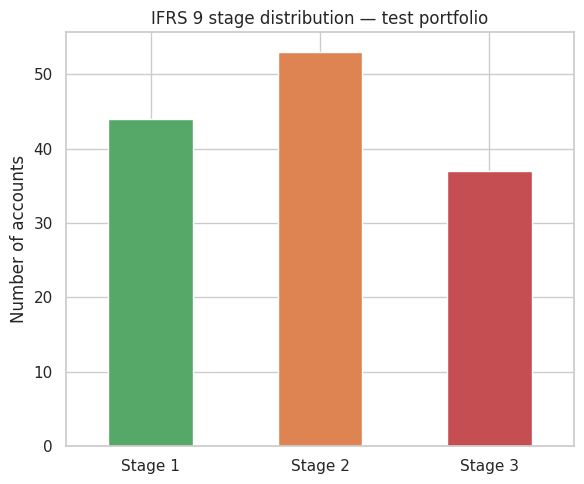

In [14]:
fig, ax = plt.subplots(figsize=(6, 5))
colors = {"Stage 1": "#55A868", "Stage 2": "#DD8452", "Stage 3": "#C44E52"}
stage_summary["n_accounts"].plot(kind="bar", ax=ax,
                                 color=[colors[s] for s in stage_summary.index])
ax.set_ylabel("Number of accounts")
ax.set_title("IFRS 9 stage distribution — test portfolio")
ax.set_xlabel("")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 6. Expected Credit Loss (ECL) calculation

The core IFRS 9 formula applied at account level:

$$\text{ECL} = \text{PD} \times \text{LGD} \times \text{EAD}$$

- **PD (Probability of Default)** — the modelled 12-month PD from Section 4. For Stage 2/3
  accounts, IFRS 9 requires a **lifetime PD**; here we proxy lifetime PD by scaling the 12-month PD
  up (a simplified but directionally-consistent approach to reflect the longer loss-emergence
  horizon — in production this would come from a term-structure / survival model).
- **LGD (Loss Given Default)** — the proportion of exposure expected to be lost if default occurs.
  We apply illustrative LGD assumptions that vary by **collateral / property status**, consistent
  with how secured vs. unsecured retail exposures are typically differentiated.
- **EAD (Exposure at Default)** — approximated here by the outstanding `credit_amount`, a standard
  simplification for term loans without revolving drawdown risk.

### Macroeconomic overlay / stress scenario

IFRS 9 also requires **forward-looking, probability-weighted macroeconomic scenarios** (base,
upside, downside) to be incorporated into ECL — not just point-in-time estimates. We apply an
illustrative **downside stress multiplier** to PDs (representing, e.g., a rise in unemployment and
falling house prices, similar to a Bank of England annual cyclical scenario) and compare base-case
vs. stressed ECL.


In [15]:
# --- LGD assumptions (illustrative, vary by collateral position) ---------------------------
def assign_lgd(row):
    if row["property"] == "real estate":
        return 0.30           # secured by real estate -> lower loss given default
    elif row["property"] == "building society savings / life insurance":
        return 0.40           # partially secured
    elif row["property"] == "car or other (not in savings)":
        return 0.55
    else:
        return 0.65           # unsecured / unknown property -> highest LGD

scored["lgd"] = scored.apply(assign_lgd, axis=1)

# --- EAD: outstanding balance (illustrative simplification for term loans) ------------------
scored["ead"] = scored["credit_amount"].astype(float)

# --- Lifetime PD proxy for Stage 2 / Stage 3 (simplified term-structure scaling) ------------
LIFETIME_SCALAR = 2.5
scored["pd_for_ecl"] = np.where(
    scored["ifrs9_stage"] == "Stage 1",
    scored["pd_12m"],
    np.minimum(scored["pd_12m"] * LIFETIME_SCALAR, 1.0),
)

# --- Base-case ECL ---------------------------------------------------------------------------
scored["ecl_base"] = scored["pd_for_ecl"] * scored["lgd"] * scored["ead"]

# --- Downside macroeconomic stress overlay --------------------------------------------------
# Illustrative: a moderate UK recession scenario lifts PDs by ~35% (e.g. rising unemployment,
# tightening household budgets) -- loosely calibrated to the order of magnitude seen in BoE
# annual cyclical scenario PD shocks for retail unsecured/secured portfolios.
STRESS_PD_MULTIPLIER = 1.35
scored["pd_stressed"] = np.minimum(scored["pd_for_ecl"] * STRESS_PD_MULTIPLIER, 1.0)
scored["ecl_stressed"] = scored["pd_stressed"] * scored["lgd"] * scored["ead"]

scored[["ifrs9_stage", "pd_12m", "pd_for_ecl", "lgd", "ead", "ecl_base", "pd_stressed", "ecl_stressed"]].head(10)


,ifrs9_stage,pd_12m,pd_for_ecl,lgd,ead,ecl_base,pd_stressed,ecl_stressed
438,Stage 2,0.703380,1.000000,0.55,3394.0,1866.700000,1.000000,1866.700000
297,Stage 1,0.044048,0.044048,0.40,1287.0,22.676105,0.059465,30.612741
386,Stage 1,0.078170,0.078170,0.30,1126.0,26.405974,0.105530,35.648065
71,Stage 2,0.030177,0.075442,0.40,730.0,22.029125,0.101847,29.739319
452,Stage 1,0.062855,0.062855,0.40,2759.0,69.366321,0.084854,93.644533
171,Stage 1,0.135524,0.135524,0.30,763.0,31.021498,0.182958,41.879022
421,Stage 1,0.079326,0.079326,0.55,2028.0,88.480666,0.107091,119.448899
277,Stage 1,0.082131,0.082131,0.40,1262.0,41.459531,0.110876,55.970367
30,Stage 1,0.254790,0.254790,0.30,1913.0,146.223793,0.343966,197.402121
192,Stage 3,0.293961,0.734903,0.55,3915.0,1582.429984,0.992119,2136.280478


In [16]:
portfolio = scored.groupby("ifrs9_stage").agg(
    n_accounts=("ead", "size"),
    total_exposure=("ead", "sum"),
    base_ecl=("ecl_base", "sum"),
    stressed_ecl=("ecl_stressed", "sum"),
).reindex(["Stage 1", "Stage 2", "Stage 3"])

portfolio["base_coverage_ratio_pct"] = (portfolio["base_ecl"] / portfolio["total_exposure"] * 100).round(2)
portfolio["stressed_coverage_ratio_pct"] = (portfolio["stressed_ecl"] / portfolio["total_exposure"] * 100).round(2)
portfolio["ecl_uplift_pct"] = ((portfolio["stressed_ecl"] / portfolio["base_ecl"] - 1) * 100).round(1)

for col in ["total_exposure", "base_ecl", "stressed_ecl"]:
    portfolio[col] = portfolio[col].round(0)

portfolio


,n_accounts,total_exposure,base_ecl,stressed_ecl,base_coverage_ratio_pct,stressed_coverage_ratio_pct,ecl_uplift_pct
ifrs9_stage,,,,,,,
Stage 1,44,101603.0,3624.0,4892.0,3.57,4.82,35.0
Stage 2,53,173480.0,64982.0,68360.0,37.46,39.41,5.2
Stage 3,37,141939.0,63040.0,66550.0,44.41,46.89,5.6


In [17]:
totals = portfolio[["total_exposure", "base_ecl", "stressed_ecl"]].sum()
print("Portfolio summary (test sample, illustrative monetary units):")
print(f"  Total exposure (EAD) ............ {totals['total_exposure']:>12,.0f}")
print(f"  Base-case ECL ................... {totals['base_ecl']:>12,.0f}   "
      f"({totals['base_ecl'] / totals['total_exposure']:.2%} coverage)")
print(f"  Stressed (downside) ECL ......... {totals['stressed_ecl']:>12,.0f}   "
      f"({totals['stressed_ecl'] / totals['total_exposure']:.2%} coverage)")
print(f"  ECL uplift under stress ......... {(totals['stressed_ecl']/totals['base_ecl'] - 1):.1%}")


Portfolio summary (test sample, illustrative monetary units):
  Total exposure (EAD) ............      417,022
  Base-case ECL ...................      131,646   (31.57% coverage)
  Stressed (downside) ECL .........      139,802   (33.52% coverage)
  ECL uplift under stress ......... 6.2%


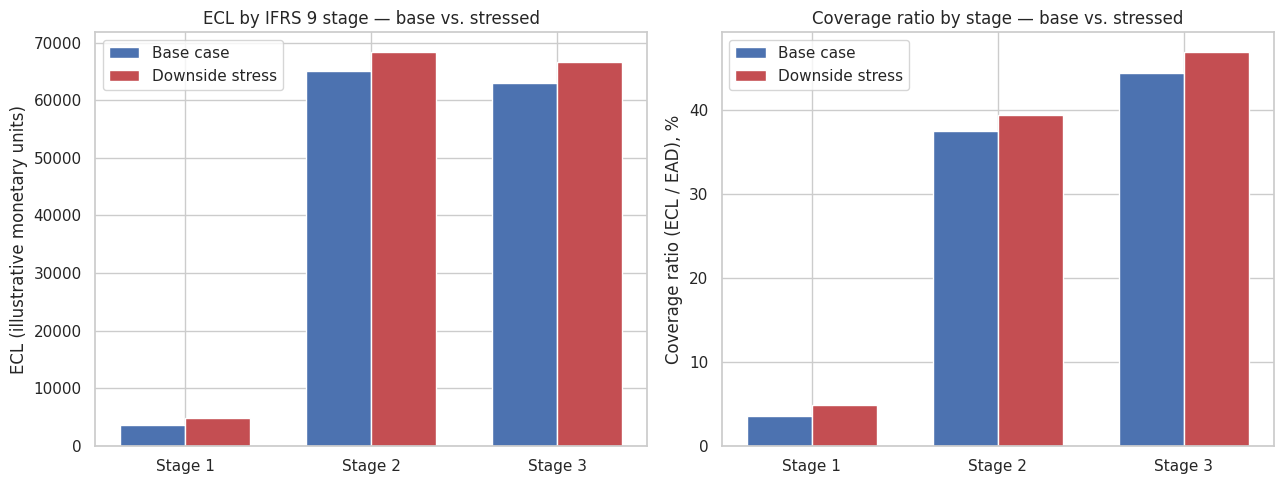

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

x = np.arange(len(portfolio))
width = 0.35
axes[0].bar(x - width/2, portfolio["base_ecl"], width, label="Base case", color="#4C72B0")
axes[0].bar(x + width/2, portfolio["stressed_ecl"], width, label="Downside stress", color="#C44E52")
axes[0].set_xticks(x)
axes[0].set_xticklabels(portfolio.index)
axes[0].set_ylabel("ECL (illustrative monetary units)")
axes[0].set_title("ECL by IFRS 9 stage — base vs. stressed")
axes[0].legend()

axes[1].bar(x - width/2, portfolio["base_coverage_ratio_pct"], width, label="Base case", color="#4C72B0")
axes[1].bar(x + width/2, portfolio["stressed_coverage_ratio_pct"], width, label="Downside stress", color="#C44E52")
axes[1].set_xticks(x)
axes[1].set_xticklabels(portfolio.index)
axes[1].set_ylabel("Coverage ratio (ECL / EAD), %")
axes[1].set_title("Coverage ratio by stage — base vs. stressed")
axes[1].legend()

plt.tight_layout()
plt.show()


## 7. Worked example — scoring a single new application

A practical end-to-end illustration of how this pipeline would be used operationally: take one
application from the test set, run it through the production PD model, assign its IFRS 9 stage,
and compute its individual ECL contribution.


In [19]:
sample_idx = scored.sort_values("pd_12m", ascending=False).index[2]   # a higher-risk example
sample = scored.loc[[sample_idx]]

print("Applicant profile:")
profile_cols = ["checking_account_status", "duration_months", "credit_history", "purpose",
                "credit_amount", "savings_account", "employment_since", "age_years",
                "housing", "job"]
for c in profile_cols:
    print(f"  {c:28s}: {X_test.loc[sample_idx, c]}")

print("\nModel outputs:")
print(f"  12-month PD ..................... {sample['pd_12m'].iloc[0]:.1%}")
print(f"  IFRS 9 stage .................... {sample['ifrs9_stage'].iloc[0]}")
print(f"  PD applied for ECL .............. {sample['pd_for_ecl'].iloc[0]:.1%}")
print(f"  LGD assumption .................. {sample['lgd'].iloc[0]:.0%}")
print(f"  EAD ............................. {sample['ead'].iloc[0]:,.0f}")
print(f"  --> Base-case ECL ............... {sample['ecl_base'].iloc[0]:,.1f}")
print(f"  --> Stressed (downside) ECL ..... {sample['ecl_stressed'].iloc[0]:,.1f}")
print(f"\n  Actual outcome on file: {'DEFAULTED' if sample['actual_default'].iloc[0] else 'repaid in full'}")


Applicant profile:
  checking_account_status     : 0 to < 200 DM
  duration_months             : 36
  credit_history              : existing credits paid duly till now
  purpose                     : car (new)
  credit_amount               : 14318
  savings_account             : < 100 DM
  employment_since            : >= 7 years
  age_years                   : 57
  housing                     : for free
  job                         : management/self-employed/highly qualified

Model outputs:
  12-month PD ..................... 90.7%
  IFRS 9 stage .................... Stage 3
  PD applied for ECL .............. 100.0%
  LGD assumption .................. 65%
  EAD ............................. 14,318
  --> Base-case ECL ............... 9,306.7
  --> Stressed (downside) ECL ..... 9,306.7

  Actual outcome on file: DEFAULTED


## 8. Summary & next steps

**What this notebook demonstrates:**

- A full **PD → staging → ECL** pipeline matching the structure UK lenders use to meet **IFRS 9**
  impairment requirements, built and validated on **536 real historical loan applications** from
  the Statlog German Credit Data benchmark.
- **Benchmark/challenger PD modelling** (logistic regression vs. gradient boosting) validated with
  the **AUC** and **KS** metrics used in bank model-validation packs, plus a calibration check —
  because ECL depends on the *level* of PD, not just its rank-ordering.
- **IFRS 9 staging** using a SICR proxy that combines PD deterioration with arrears/credit-history
  backstops — the standard approach when full transition-matrix PD histories aren't available.
- **ECL = PD × LGD × EAD**, with LGD differentiated by collateral position and a **macroeconomic
  downside stress overlay**, reflecting the forward-looking, scenario-weighted approach IFRS 9
  requires (and that the PRA examines through stress testing).

**How this would be extended for production use:**

- Calibrate LGD and EAD against the lender's own historical workout/recovery data rather than
  illustrative assumptions.
- Build a proper **lifetime PD term structure** (e.g. survival analysis / Markov transition
  matrices) instead of a flat lifetime-PD scalar.
- Incorporate **probability-weighted multiple macroeconomic scenarios** (base/upside/downside)
  rather than a single stress overlay, per IFRS 9 / IFRS 9 illustrative examples.
- Add **population stability index (PSI)** monitoring to track PD model drift over time, and
  periodic **back-testing** of realised vs. predicted default and loss rates.
- Subject the model to **independent model validation** and **governance sign-off**, consistent
  with PRA SS1/23 (Model Risk Management) expectations for UK banks.
